# Sparse submatrix detection and recovery
**Amrit Chadha and Faris Doughan · STAT 236**

Each matrix has independent Gaussian entries with variance 1. A signal adds
$\mu$ to a randomly chosen set of $k$ rows and $k$ columns; these indices need
not be consecutive. Detection asks whether a signal is present. Recovery asks
for both index sets exactly.

We generate labeled matrices, define the methods, and compare their errors.
All experiments run from top to bottom, with seed **236** and **600 matrices
per condition**. The final section varies $n$ to illustrate an asymptotic regime.

In [1]:
from functools import cache
from itertools import combinations
from math import ceil, comb

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from threadpoolctl import threadpool_limits

blas_limit = threadpool_limits(limits=1)
rng = np.random.default_rng(236)
REPS = 600
CALIBRATION_REPS = 1500
ALPHA = 0.05

## 1. Create the data

We cross $n\in\{12,16\}$ with $\gamma\in\{.4,.75\}$ and set
$k=\lfloor n^\gamma\rfloor$: $(n,k)=(12,2),(12,6),(16,3),(16,8)$.
This includes blocks smaller and larger than $\sqrt n$, while keeping exact
scanning feasible. Each configuration has 600 null matrices and 600 planted
matrices at each listed positive signal strength.

`signal` is 0 or 1; `mu`, `rows`, and `cols` record the truth. `X` contains
the matrix. The methods receive only `X` and the known block size `k`.

In [2]:
def make_matrix(n, k, mu, signal, rng):
    X = rng.standard_normal((n, n))
    rows = cols = np.array([], dtype=int)
    if signal:
        rows = np.sort(rng.choice(n, k, replace=False))
        cols = np.sort(rng.choice(n, k, replace=False))
        X[np.ix_(rows, cols)] += mu
    return X, rows, cols


configs = [(n, gamma, int(n**gamma))
           for n in [12, 16] for gamma in [0.4, 0.75]]
mus = [0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0, 4.0]
records = []
for n, gamma, k in configs:
    for mu in [0.0] + mus:
        signal = int(mu > 0)
        for _ in range(REPS):
            X, rows, cols = make_matrix(n, k, mu, signal, rng)
            records.append((n, k, gamma, signal, mu, rows, cols, X))

data = pd.DataFrame(records, columns=[
    'n', 'k', 'gamma', 'signal', 'mu', 'rows', 'cols', 'X'])
data.index.name = 'matrix_id'
# Show one null and one planted example per configuration, without printing X.
data.groupby(['n', 'k', 'signal']).head(1).drop(columns='X')

,n,k,gamma,signal,mu,rows,cols
matrix_id,,,,,,,
0,12,2,0.40,0,0.00,[],[]
600,12,2,0.40,1,0.25,"[1, 10]","[0, 1]"
5400,12,6,0.75,0,0.00,[],[]
6000,12,6,0.75,1,0.25,"[1, 2, 6, 9, 10, 11]","[0, 4, 6, 8, 9, 11]"
10800,16,3,0.40,0,0.00,[],[]
11400,16,3,0.40,1,0.25,"[2, 12, 13]","[0, 1, 8]"
16200,16,8,0.75,0,0.00,[],[]
16800,16,8,0.75,1,0.25,"[0, 5, 6, 7, 10, 11, 12, 14]","[0, 3, 5, 7, 8, 9, 10, 15]"


## 2. Define the methods

The four detectors use the **sum**, **scan**, **maximum entry**, and
**sum+scan**. The sum is divided by $n$, and each scanned block sum by $k$,
so a fixed block has null variance 1. For every possible row set, the scan
selects the $k$ largest column sums. This searches all blocks exactly.
Its maximizing row and column sets also give exhaustive recovery.

Spectral recovery selects the largest row and column scores from the leading
singular vectors. For small blocks ($k^2<n$), we also apply it after soft
thresholding at $\sqrt{2\log(n/k^2)}$. Recovery is wrong if either index set
is wrong; partial overlap does not count as exact recovery.

In [3]:
def sum_stat(X):
    return X.sum() / len(X)


def max_stat(X):
    return X.max()


@cache
def row_subsets(n, k):
    if comb(n, k) > 20000:
        raise ValueError('Exact scan is too large for this notebook.')
    return np.array(list(combinations(range(n), k)))


def scan(X, k):
    rows = row_subsets(len(X), k)
    column_sums = X[rows].sum(axis=1)
    cols = np.argsort(column_sums, axis=1)[:, -k:]
    block_sums = np.take_along_axis(column_sums, cols, axis=1).sum(axis=1)
    best = block_sums.argmax()
    return block_sums[best] / k, rows[best], np.sort(cols[best])


def spectral(X, k, threshold=0.0):
    Y = np.sign(X) * np.maximum(np.abs(X) - threshold, 0)
    U, _, Vt = np.linalg.svd(Y, full_matrices=False)
    u, v = U[:, 0].copy(), Vt[0].copy()
    if u.sum() < 0:  # Resolve the arbitrary common sign of the singular vectors.
        u, v = -u, -v
    rows = np.sort(np.argsort(Y @ v)[-k:])
    cols = np.sort(np.argsort(Y.T @ u)[-k:])
    return rows, cols


def recovery_error(estimated, rows, cols):
    return int(not (np.array_equal(estimated[0], rows)
                    and np.array_equal(estimated[1], cols)))

### Detection cutoffs

Each detector has target false-positive rate .05. Sum and maximum use their
exact Gaussian null distributions. The scan uses 1,500 separate null matrices
per configuration, drawn independently of the evaluation data. Sum+scan
rejects when either component exceeds its **.025** cutoff (Bonferroni).

In [4]:
def scan_cutoff(null_stats, alpha):
    # Upper order statistic: conservative for a new independent null matrix.
    index = ceil((len(null_stats) + 1) * (1 - alpha)) - 1
    return np.sort(null_stats)[index]


cutoffs = {}
for n, gamma, k in configs:
    null_scan = [scan(rng.standard_normal((n, n)), k)[0]
                 for _ in range(CALIBRATION_REPS)]
    cutoffs[n, k] = {
        'sum': norm.isf(ALPHA),
        'max': norm.ppf((1 - ALPHA)**(1 / n**2)),
        'scan': scan_cutoff(null_scan, ALPHA),
        'sum_half': norm.isf(ALPHA / 2),
        'scan_half': scan_cutoff(null_scan, ALPHA / 2),
    }

## 3. Run the methods

All four detectors see every matrix. Recovery runs only on planted matrices.
We keep each decision beside its matrix's truth; exhaustive recovery reuses
the scan result. Soft spectral runs only in the small-block configurations.

In [5]:
decisions, recovery = [], []
for d in data.itertuples():
    c = cutoffs[d.n, d.k]
    total, maximum = sum_stat(d.X), max_stat(d.X)
    scanned, rows_hat, cols_hat = scan(d.X, d.k)
    decisions.append((total > c['sum'], scanned > c['scan'],
                      maximum > c['max'],
                      total > c['sum_half'] or scanned > c['scan_half']))
    if d.signal:
        exhaustive = recovery_error((rows_hat, cols_hat), d.rows, d.cols)
        svd = recovery_error(spectral(d.X, d.k), d.rows, d.cols)
        soft = np.nan
        if d.k**2 < d.n:
            threshold = np.sqrt(2 * np.log(d.n / d.k**2))
            soft = recovery_error(spectral(d.X, d.k, threshold), d.rows, d.cols)
        recovery.append((d.Index, exhaustive, svd, soft))

detectors = ['sum', 'scan', 'max', 'sum+scan']
predictions = pd.DataFrame(decisions, columns=detectors, index=data.index)
detection = data[['n', 'k', 'signal', 'mu']].join(predictions)
recovery = pd.DataFrame(recovery, columns=[
    'matrix_id', 'exhaustive', 'spectral', 'soft spectral']).set_index('matrix_id')
recovery = data[['n', 'k', 'mu']].join(recovery, how='inner')

### Detection error versus signal strength

Error is $\tfrac12(\text{false-positive rate}+\text{false-negative rate})$,
so guessing gives .5. The same null sample supplies the false-positive rate
for every $\mu$ within a configuration. A false-positive rate of .05 leaves
error .025 even with perfect power. The paper's total testing risk is twice this error.

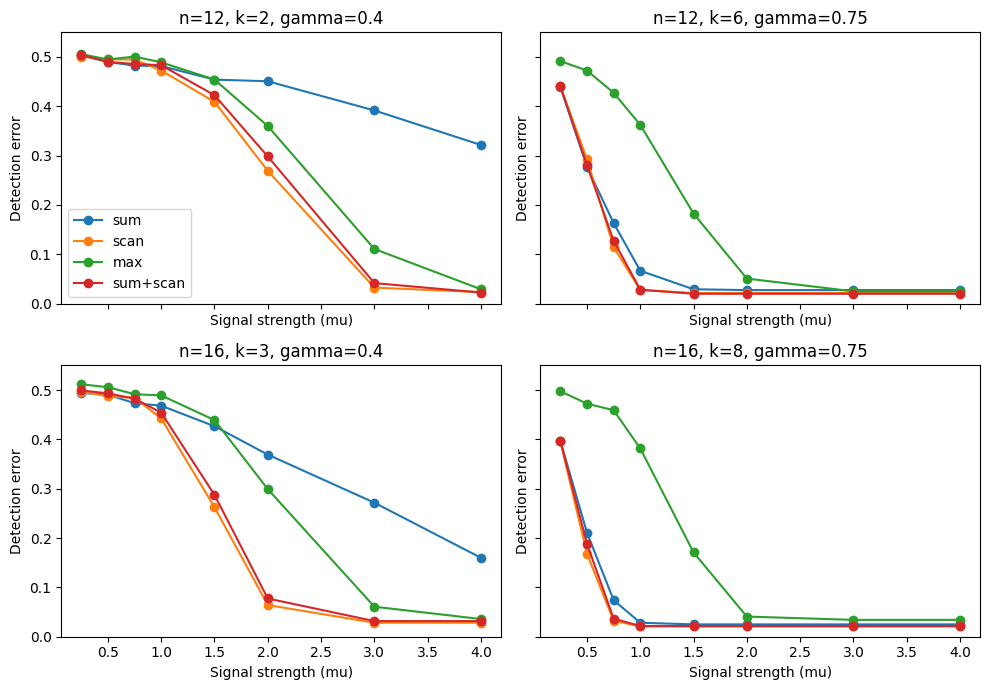

In [6]:
errors = []
for (n, k), group in detection.groupby(['n', 'k']):
    false_positive = group.loc[group.signal == 0, detectors].mean()
    for mu, planted in group[group.signal == 1].groupby('mu'):
        error = (false_positive + 1 - planted[detectors].mean()) / 2
        errors.append({'n': n, 'k': k, 'mu': mu, **error.to_dict()})
detection_error = pd.DataFrame(errors)

fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True)
for ax, (n, gamma, k) in zip(axes.flat, configs):
    points = detection_error.query('n == @n and k == @k')
    for method in detectors:
        ax.plot(points.mu, points[method], 'o-', label=method)
    ax.set(title=f'n={n}, k={k}, gamma={gamma}', ylim=(0, 0.55),
           xlabel='Signal strength (mu)', ylabel='Detection error')
axes[0, 0].legend()
fig.tight_layout()
plt.show()

### Exact recovery error versus signal strength

An error of 0 means every planted block was identified exactly; 1 means none
were. Comparing the same $n$ across the two block sizes shows the effect of
sparsity. Curves summarize 600 trials per point; small differences can be sampling noise.

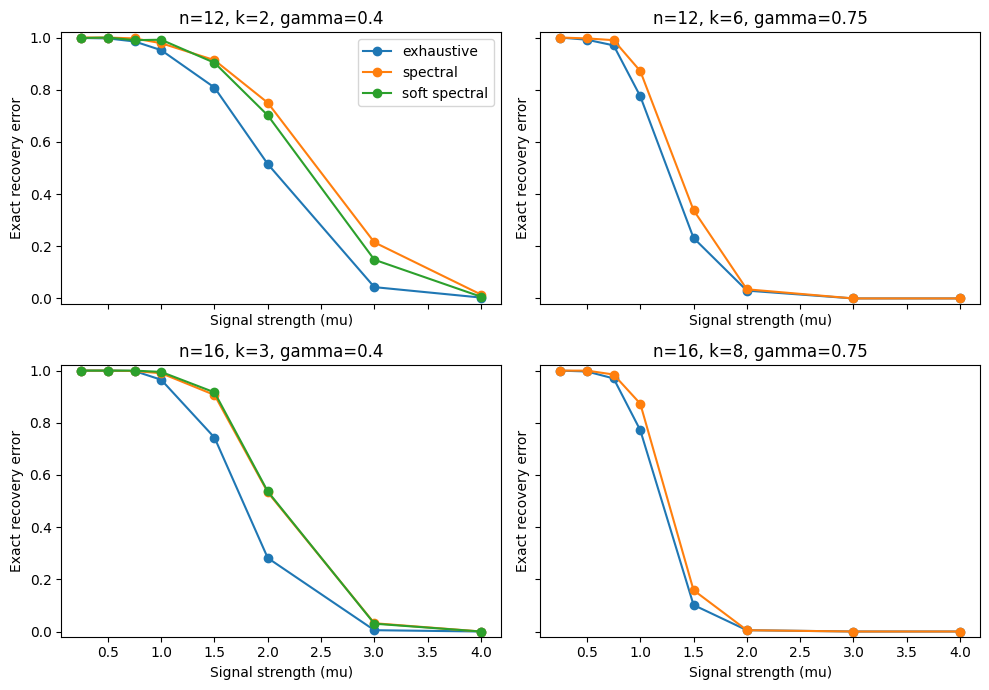

In [7]:
recovery_error_rates = recovery.groupby(['n', 'k', 'mu'])[
    ['exhaustive', 'spectral', 'soft spectral']].mean().reset_index()

fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True)
for ax, (n, gamma, k) in zip(axes.flat, configs):
    points = recovery_error_rates.query('n == @n and k == @k')
    for method in ['exhaustive', 'spectral', 'soft spectral']:
        if points[method].notna().any():
            ax.plot(points.mu, points[method], 'o-', label=method)
    ax.set(title=f'n={n}, k={k}, gamma={gamma}', ylim=(-0.02, 1.02),
           xlabel='Signal strength (mu)', ylabel='Exact recovery error')
axes[0, 0].legend()
fig.tight_layout()
plt.show()

## 4. Increase n along one asymptotic regime

Set $k=\lfloor n^{.75}\rfloor$ and $\mu=n^{-\beta}$. The sum's mean shift
is $\mu k^2/n\asymp n^{.5-\beta}$: it grows for $\beta=0,.25$ and vanishes
for $\beta=.75$. We use level $\alpha_n=1/n$ so false positives also vanish.
Spectral recovery has sufficient signal scale
$\sqrt n/k+\sqrt{\log(n)/k}$, which tends to zero here. Fixed $\mu=1$
should eventually succeed; the two decaying signals need not.

For each $(n,\beta)$, generate 600 null and 600 planted matrices and test the
sum and spectral recovery. Large matrices are processed one at a time.
The four-detector comparison above stays at sizes where scanning is feasible.
These finite sequences illustrate trends; they do not prove asymptotic limits
or computational lower bounds.

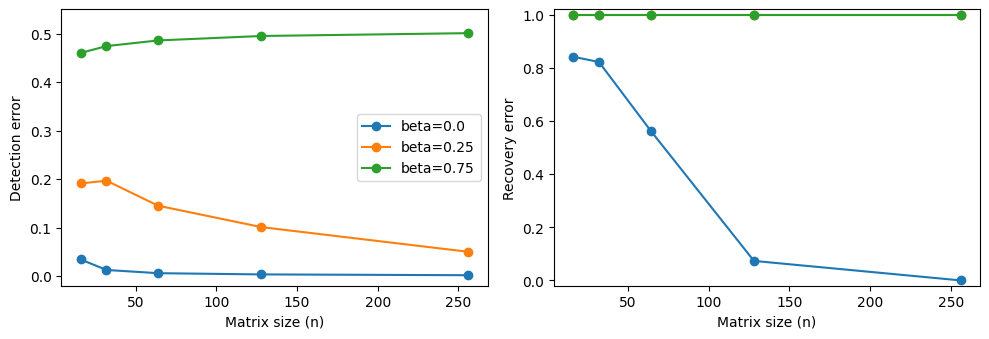

In [8]:
growing_results = []
for n in [16, 32, 64, 128, 256]:
    k = int(n**0.75)
    cutoff = norm.isf(1 / n)
    for beta in [0.0, 0.25, 0.75]:
        mu = n**(-beta)
        detection_mistakes, recovery_mistakes = [], []
        for signal in [0, 1]:
            for _ in range(REPS):
                X, rows, cols = make_matrix(n, k, mu * signal, signal, rng)
                detection_mistakes.append(int((sum_stat(X) > cutoff) != signal))
                if signal:
                    recovery_mistakes.append(recovery_error(
                        spectral(X, k), rows, cols))
        growing_results.append((n, k, beta, mu,
                                np.mean(detection_mistakes),
                                np.mean(recovery_mistakes)))
growing = pd.DataFrame(growing_results, columns=[
    'n', 'k', 'beta', 'mu', 'detection error', 'recovery error'])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for beta, points in growing.groupby('beta'):
    for ax, metric in zip(axes, ['detection error', 'recovery error']):
        ax.plot(points.n, points[metric], 'o-', label=f'beta={beta}')
        ax.set(xlabel='Matrix size (n)', ylabel=metric.capitalize(),
               ylim=(-0.02, 0.55 if metric == 'detection error' else 1.02))
axes[0].legend()
fig.tight_layout()
plt.show()

For $\beta=0$, both errors decrease as $n$ grows. For $\beta=.25$, detection
improves, but spectral recovery still fails at these sizes. For $\beta=.75$,
detection approaches error .5 and spectral recovery fails throughout.